# 04 — hsc

**Purpose:** Reproduce the manuscript figure panels from already generated numerical tables. This notebook does not fit scCHART or regenerate the simulations. The computational pipelines are in `scripts/`.

In [1]:
from pathlib import Path
from types import SimpleNamespace
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Work whether launched from the repository root or its notebooks/ directory.
ROOT = Path.cwd().resolve()
if not (ROOT / "results").is_dir() and (ROOT.parent / "results").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "results").is_dir(), "Open from scCHART_analysis/ or notebooks/"
FIG_ROOT = ROOT / "figures"
MM = 1 / 25.4
FS_LETTER, FS_LABEL, FS_TICK, FS_ANN, FS_SMALL, FS_MIN = 8, 7, 6, 6, 5.5, 5
LW_AX, LW_DATA = 0.5, 1.0
STRUCT, STRUCT_L = "#3A4F8C", "#A9BCD0"
PROG, PROG_L = "#2A9070", "#9FD3C7"
EPI, JAC = "#C0632B", "#8C8C8C"
INK, MUTED, GUIDE = "#1A1A1A", "#555555", "#C8C8C8"
NEUTRAL_L = "#BDBDBD"

def apply_style() -> None:
    """Matplotlib settings of the frozen figures (Arial, 5-8 pt, editable text in SVG/PDF)."""
    import matplotlib._mathtext as mathtext
    mathtext.SHRINK_FACTOR = 0.84            # sub/superscripts of 6 pt text stay >= 5 pt
    mpl.rcParams.update({
        "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica"], "font.size": FS_TICK,
        "mathtext.fontset": "custom", "mathtext.rm": "Arial", "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold", "mathtext.sf": "Arial", "mathtext.default": "it",
        "axes.labelsize": FS_LABEL, "axes.titlesize": FS_LABEL, "axes.titlepad": 3,
        "axes.linewidth": LW_AX, "axes.edgecolor": INK, "axes.labelcolor": INK, "axes.labelpad": 2,
        "axes.spines.top": False, "axes.spines.right": False,
        "xtick.labelsize": FS_TICK, "ytick.labelsize": FS_TICK, "xtick.major.width": LW_AX,
        "ytick.major.width": LW_AX, "xtick.major.size": 2, "ytick.major.size": 2, "xtick.major.pad": 1.5,
        "ytick.major.pad": 1.5, "xtick.color": INK, "ytick.color": INK,
        "legend.fontsize": FS_ANN, "legend.frameon": False, "legend.handletextpad": 0.4,
        "legend.borderaxespad": 0.2, "legend.labelspacing": 0.25,
        "lines.linewidth": LW_DATA, "lines.markersize": 2.6, "errorbar.capsize": 0,
        "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 600,
        "figure.facecolor": "white", "savefig.facecolor": "white",
    })

class Canvas:
    """A figure laid out in millimetres, origin at the top-left corner."""

    def __init__(self, width_mm: float, height_mm: float):
        import matplotlib.pyplot as plt
        self.fig = plt.figure(figsize=(width_mm * MM, height_mm * MM))
        # Matplotlib rounds the figure size to whole pixels (183 mm -> 7.2 in); positions are computed from the
        # realised size, as in the frozen figures, so element coordinates match them exactly.
        self.W, self.H = (v / MM for v in self.fig.get_size_inches())

    def ax(self, x, y, w, h, **kw):
        return self.fig.add_axes([x / self.W, 1 - (y + h) / self.H, w / self.W, h / self.H], **kw)

    def text(self, x, y, s, **kw):
        kw.setdefault("fontsize", FS_ANN); kw.setdefault("va", "top"); kw.setdefault("color", INK)
        return self.fig.text(x / self.W, 1 - y / self.H, s, **kw)

    def letter(self, x, y, s):
        return self.text(x, y, s, fontsize=FS_LETTER, fontweight="bold", ha="left")

    def legend_at(self, handles, x, y, **kw):
        """Figure legend whose top centre is at (x, y) mm."""
        return self.fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(x / self.W, 1 - y / self.H),
                               borderaxespad=0, **kw)

class Region:
    """A panel region of a Canvas: the same placement calls, in mm relative to the region's top-left corner."""

    def __init__(self, cv: Canvas, x0: float, y0: float):
        self.cv, self.x0, self.y0, self.fig = cv, x0, y0, cv.fig

    def ax(self, x, y, w, h, **kw):
        return self.cv.ax(self.x0 + x, self.y0 + y, w, h, **kw)

    def text(self, x, y, s, **kw):
        return self.cv.text(self.x0 + x, self.y0 + y, s, **kw)

    def letter(self, s):
        return self.cv.letter(self.x0, self.y0, s)

    def head(self, x, y, s, w=None, color=None, fontsize=None):
        """Bold section heading, optionally underlined by a guide rule of width w mm."""
        self.text(x, y, s, fontsize=fontsize or FS_ANN, fontweight="bold", color=color or INK)
        if w:
            a = self.ax(x, y + 3.4, w, 0.4); a.set_xlim(0, 1); a.set_ylim(0, 1); blank(a)
            a.plot([0, 1], [0.5, 0.5], c=GUIDE, lw=0.5)

def label(ax, s, **kw):
    """Plain left-aligned label above an axes."""
    ax.set_title(s, loc=kw.pop("loc", "left"), fontsize=kw.pop("fontsize", FS_ANN), color=INK, pad=kw.pop("pad", 2), **kw)

def halo(width=1.4):
    import matplotlib.patheffects as pe
    return [pe.withStroke(linewidth=width, foreground="white")]

def fmt_p(p, sym="P"):
    """P = 0.56, P = 0.015, P = 4.7 × 10⁻⁴ (mathtext superscript), as printed on the frozen figures."""
    import numpy as np
    if p >= 0.01:
        s = f"{p:.2f}" if p >= 0.1 else f"{p:#.2g}"
        return f"{sym} = {s}"
    e = int(np.floor(np.log10(p))); m = p / 10 ** e
    if round(m, 1) >= 10:
        m, e = m / 10, e + 1
    return f"{sym} = {m:.1f} × 10$^{{{e}}}$"

def short(g: str) -> str:
    """Granja population id -> display name ('01_HSC' -> 'HSC'; unannotated clusters -> 'Unk 13')."""
    return "Unk " + g.split("_")[0] if g.endswith("Unk") else g.split("_", 1)[1]

def blank(ax) -> None:
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

# Manuscript source names -> directories in the public analysis repository.
RESULT_DIRS = {
    "01_synthetic_benchmarks": "01_benchmarks",
    "02_hematopoiesis": "02_granja",
    "03_CATLAS_programmes": "03_catlas",
    "04_xenograft_HSC": "04_hsc",
    "05_method_comparisons": "05_method_comparisons",
}

def result_path(rel):
    parts = Path(rel).parts
    if len(parts) >= 3 and parts[1] == "results":
        return ROOT / "results" / RESULT_DIRS.get(parts[0], parts[0]) / Path(*parts[2:])
    return ROOT / rel

def read(rel, cols=None, n_rows=None):
    path = result_path(rel)
    df = pd.read_csv(path, sep="\t")
    if cols:
        missing = set(cols) - set(df.columns)
        assert not missing, f"{path}: missing {sorted(missing)}"
    if n_rows is not None:
        assert len(df) == n_rows, f"{path}: {len(df)} rows, expected {n_rows}"
    return df

def printed(panel, quantity, exact, fmt, source, flag=False):
    # Format a value read from a result table; no frozen-manuscript comparisons.
    return fmt(exact) if callable(fmt) else (format(exact, fmt) if fmt else str(exact))

OUTPUT_DIR = FIG_ROOT / "02_granja"  # notebook section sets this explicitly.

def save(fig, name):
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for ext, opts in (("pdf", {}), ("svg", {}), ("png", {"dpi": 300})):
        path = OUTPUT_DIR / f"{name}.{ext}"
        fig.savefig(path, **opts)
        print(path.relative_to(ROOT))

def build(name, size_mm, panels):
    cv = Canvas(*size_mm)
    for letter, x, y, draw in panels:
        region = Region(cv, x, y)
        draw(region)
        if letter:
            region.letter(letter)
    save(cv.fig, name)
    return cv

fs = SimpleNamespace(**{k: globals()[k] for k in (
    "apply_style", "Canvas", "Region", "label", "halo", "fmt_p", "short", "blank",
    "read", "save", "build", "printed", "ROOT", "STRUCT", "STRUCT_L", "PROG", "PROG_L",
    "EPI", "JAC", "INK", "MUTED", "GUIDE", "NEUTRAL_L", "FS_LETTER", "FS_LABEL",
    "FS_TICK", "FS_ANN", "FS_SMALL", "FS_MIN")})
apply_style()


## Figure 4

**Scientific question.** Can per-cell structural and programme contributions resolve a continuous axis among HSCs, and is it linked to substate composition, differential accessibility and enriched motif families? Figures display the saved HSC analysis outputs.

In [2]:
OUTPUT_DIR = ROOT / "figures" / "04_hsc"
FS_LETTER, FS_LABEL, FS_TICK, FS_ANN, FS_SMALL, FS_MIN = (fs.FS_LETTER,fs.FS_LABEL,fs.FS_TICK,fs.FS_ANN,fs.FS_SMALL,fs.FS_MIN)
GUIDE, INK, MUTED = fs.GUIDE, fs.INK, fs.MUTED
PROG, PROG_L, STRUCT, STRUCT_L = fs.PROG, fs.PROG_L, fs.STRUCT, fs.STRUCT_L
EPI, JAC, NEUTRAL_L = fs.EPI, fs.JAC, fs.NEUTRAL_L
fmt_p, short = fs.fmt_p, fs.short

import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
SIZE = (183, 188)
PANELS = {"a": (0, 0, 106, 52), "b": (107, 0, 76, 55), "c": (0, 58, 58, 64), "d": (59, 58, 64, 64),
          "e": (124, 58, 59, 64), "f": (0, 128, 92, 56), "g": (93, 128, 90, 58)}
PANEL_REGIONS = PANELS
HSC1, HSC2 = "#B06E12", "#7B3F72"
STATE = {"HSC-I": HSC1, "HSC-II": HSC2}
HH, LL = "#2B2B2B", "#9C9C9C"
OPEN, CLOSED = "#B2443A", "#2F5597"
TREAT = {"PBS": "#555555", "TNF": "#9C7A3C", "LPS": "#5E7FA6"}
ADD_C = "#6B4C9A"
G_ROWS = ["GATA1::TAL1", "GATA", "NFI", "NF-κB/REL", "AP-1/BATF/BACH", "IRF", "SPI/PU.1", "BACH/NFE2 (CNC)", "CTCF"]
G_NOTE = ("Hit counts and the set and order of families with q < 0.05 match the frozen figure. Odds ratios, confidence "
          "limits and q values come from 04_xenograft_HSC/scripts/s04_hsc_motif_families.py (Mantel-Haenszel with continuity "
          "correction, strata GC x accessibility x width, Benjamini-Hochberg within the region set). They differ from the "
          "frozen figure by up to 0.01 in OR and CI and by 5-25 % in q (all lower here). The cause is not established; "
          "candidate sources are the stratum boundaries or the family set entering the BH correction.")
R4 = "04_xenograft_HSC/results/"
atlas = fs.read(R4 + "hsc_atlas_cell_contributions.tsv.gz", ["cell", "broad_population", "umap_atac_1", "umap_atac_2"])
atlas = atlas.rename(columns={"umap_atac_1": "umap1", "umap_atac_2": "umap2"})
joint = fs.read(R4 + "hsc_cell_joint_scores.tsv.gz", ["cell", "state", "treatment", "d_S", "d_P", "z_decile"], 5967)
dec = fs.read(R4 + "hsc_HSCII_share_by_zJ_decile.tsv", ["treatment", "z_decile", "frac_HSCII"], 40)
M = fs.read(R4 + "hsc_hh_ll_matched_cells.tsv", ["cell", "group", "treatment", "state", "z_decile"], 762)
comp = fs.read(R4 + "hsc_hh_ll_state_composition.tsv", ["group", "frac_HSCII"]).set_index("group")
da = fs.read(R4 + "hsc_da_joint_high_vs_low.tsv.gz", ["peak", "DA", "direction", "diff_frac"])
das = fs.read(R4 + "hsc_da_summary.tsv", ["contrast", "n_tested"]).set_index("contrast")
B = fs.read(R4 + "hsc_joint_da_binary_regions_x_cells.tsv.gz", ["peak"], 464).set_index("peak")
cats = fs.read(R4 + "hsc_joint_da_region_categories.tsv", ["peak", "overlap_category"], 464)
ovl = fs.read(R4 + "hsc_published_overlap_statistics.tsv", ["contrast", "region_set", "published_set", "universe", "odds_ratio"])
add = fs.read(R4 + "hsc_additional_regions.tsv", ["peak", "overlap_category", "delta_HSCI", "delta_HSCII"], 245)
wss = fs.read(R4 + "hsc_within_substate_summary.tsv", ["set", "n", "n_same_direction_both", "n_beyond_bg_5_95_both"]).set_index("set")
mot = fs.read(R4 + "hsc_motif_family_enrichment.tsv", ["region_set", "family", "MH_OR", "OR_ci_lo", "OR_ci_hi", "q", "fg_hits",
                                                      "n_regions"])
H = joint.merge(atlas[["cell", "umap1", "umap2"]], on="cell")
assert len(H) == 5967
MU = M.drop(columns=[c for c in ("umap1", "umap2") if c in M]).merge(atlas[["cell", "umap1", "umap2"]], on="cell")
NGROUP = M.group.value_counts()
assert (NGROUP == NGROUP.iloc[0]).all()
N_MATCHED = int(NGROUP.iloc[0])

### Plotting details

The functions below reproduce the manuscript design. They use the validated tables loaded above; random jitter and illustrative glyphs are display-only.

In [3]:
def zoom(ax):
    (x0, x1), (y0, y1) = np.quantile(H.umap1, [0.005, 0.995]), np.quantile(H.umap2, [0.005, 0.995])
    px, py = 0.04 * (x1 - x0), 0.04 * (y1 - y0)
    ax.set_xlim(x0 - px, x1 + px); ax.set_ylim(y0 - py, y1 + py); fs.blank(ax)

def title(P, x, y, s, color=None):
    P.text(x, y, s, fontsize=FS_ANN, fontweight="bold", color=color or INK)

### Panel a — Cell-level distributions

In [4]:
def panel_a(P):
    a1, a2, a3 = P.ax(2, 9, 32, 31), P.ax(37, 9, 32, 31), P.ax(72, 9, 32, 31)
    hsc = atlas.broad_population.eq("HSC")
    a1.scatter(atlas.umap1[~hsc], atlas.umap2[~hsc], s=0.08, c="#DADADA", lw=0, rasterized=True)
    a1.scatter(atlas.umap1[hsc], atlas.umap2[hsc], s=0.08, c=INK, lw=0, rasterized=True)
    fs.blank(a1); a1.set_aspect("equal", "datalim")
    n_atlas = printed("a", "atlas cells", len(atlas), ",d", R4 + "hsc_atlas_cell_contributions.tsv.gz")
    P.text(2, 2.4, f"HSPC atlas\n{n_atlas} cells; black, broad HSC", fontsize=FS_SMALL, linespacing=1.2)
    for st, c in STATE.items():
        d = H[H.state == st]; a2.scatter(d.umap1, d.umap2, s=0.3, c=c, lw=0, rasterized=True)
    zoom(a2)
    n_hsc = printed("a", "broad HSC cells", int(hsc.sum()), ",d", R4 + "hsc_atlas_cell_contributions.tsv.gz")
    n_sc = printed("a", "HSCs scored on both axes", len(H), ",d", R4 + "hsc_cell_joint_scores.tsv.gz")
    P.text(37, 2.4, f"Broad HSC population ({n_hsc});\npublished substates, {n_sc} scored", fontsize=FS_SMALL,
           linespacing=1.2)
    a3.scatter(H.umap1, H.umap2, s=0.3, c="#ECECEC", lw=0, rasterized=True)
    for g, c in (("LL", LL), ("HH", HH)):
        d = MU[MU.group == g]; a3.scatter(d.umap1, d.umap2, s=1.0, c=c, lw=0, rasterized=True, zorder=3)
    zoom(a3)
    nm = printed("a", "matched cells per group", N_MATCHED, "d", R4 + "hsc_hh_ll_matched_cells.tsv")
    P.text(72, 2.4, f"Matched extremes for d–g\nHH and LL, {nm} cells each", fontsize=FS_SMALL, linespacing=1.2)
    h = [Line2D([], [], ls="", marker="o", ms=3, mfc=c, mec=c,
                label=f"{st} ({printed('a', f'legend {st} cells', int((H.state == st).sum()), ',d', R4 + 'hsc_cell_joint_scores.tsv.gz')})")
         for st, c in STATE.items()]
    lg = P.ax(37, 42, 32, 6); fs.blank(lg)
    lg.legend(handles=h, loc="upper left", ncol=1, fontsize=FS_SMALL, handletextpad=0.1, borderaxespad=0, labelspacing=0.2)
    h2 = [Line2D([], [], ls="", marker="o", ms=3, mfc=c, mec=c, label=f"{g} ({NGROUP[g]})") for g, c in (("HH", HH), ("LL", LL))]
    lg2 = P.ax(72, 42, 32, 6); fs.blank(lg2)
    lg2.legend(handles=h2, loc="upper left", ncol=1, fontsize=FS_SMALL, handletextpad=0.1, borderaxespad=0, labelspacing=0.2)
    sh = printed("a", "HSC-II share of HH (%)", 100 * float(comp.loc["HH", "frac_HSCII"]), ".0f", R4 + "hsc_hh_ll_state_composition.tsv")
    sl = printed("a", "HSC-II share of LL (%)", 100 * float(comp.loc["LL", "frac_HSCII"]), ".0f", R4 + "hsc_hh_ll_state_composition.tsv")
    P.text(90, 42.4, f"HSC-II:\nHH {sh}%\nLL {sl}%", fontsize=FS_SMALL, linespacing=1.2)

### Panel b — Population-level rankings

In [5]:
def panel_b(P):
    for k, (col, cmap, lab, ttl, c, key) in enumerate((
            ("d_S", "Blues", "$d_i^{(S)}$ (bits)", "Structural contribution", STRUCT, "structural"),
            ("d_P", "Greens", "$d_i^{(P)}$ (bits)", "Programme contribution", PROG, "programme"))):
        ax = P.ax(2 + k * 38, 9, 34, 31)
        d = H.sort_values(col); lo, hi = np.quantile(d[col], [0.02, 0.98])
        sc = ax.scatter(d.umap1, d.umap2, s=0.3, c=d[col].clip(lo, hi), cmap=cmap, lw=0, rasterized=True, vmin=lo, vmax=hi)
        zoom(ax)
        P.text(2 + k * 38, 2.4, f"{ttl}\nper cell, uncalibrated", fontsize=FS_SMALL, fontweight="bold", color=c,
               linespacing=1.2)
        cax = P.ax(9 + k * 38, 43, 20, 1.4)
        cb = P.fig.colorbar(sc, cax=cax, orientation="horizontal"); cb.outline.set_visible(False); cb.set_ticks([])
        rng = printed("b", f"{key} colour scale", (lo, hi), lambda v: f"{v[0]:.1f} – {v[1]:.1f}",
                      R4 + "hsc_cell_joint_scores.tsv.gz (2nd and 98th percentiles)")
        lo_t, hi_t = rng.split(" – ")
        cax.text(-0.04, 0.5, lo_t, transform=cax.transAxes, ha="right", va="center", fontsize=FS_SMALL)
        cax.text(1.04, 0.5, hi_t, transform=cax.transAxes, ha="left", va="center", fontsize=FS_SMALL)
        cax.text(0.5, -1.2, lab, transform=cax.transAxes, ha="center", va="top", fontsize=FS_SMALL)
    P.text(2, 52.0, "Same embedding as a; HH/LL cells are those shown in a (right). Not depth-adjusted.", fontsize=FS_MIN)

### Panel c — Association or state composition

In [6]:
def panel_c(P):
    title(P, 4, 0.4, "HSC-II share along the joint axis")
    ax = P.ax(12, 9, 40, 28)
    for t, c in TREAT.items():
        d = dec[dec.treatment == t].sort_values("z_decile")
        ax.plot(d.z_decile + 1, 100 * d.frac_HSCII, c=c, lw=0.7, alpha=0.9, label=t)
    d = dec[dec.treatment == "all"].sort_values("z_decile")
    ax.plot(d.z_decile + 1, 100 * d.frac_HSCII, "-o", c=HSC2, ms=2.4, lw=1.6, label="All cells", zorder=3)
    ax.set(ylabel="HSC-II (% of cells)", xticks=range(1, 11), ylim=(0, 100), xlim=(0.5, 10.5))
    ax.set_xticklabels([])
    s_lo = printed("c", "HSC-II share, lowest decile (%)", 100 * float(d.frac_HSCII.iloc[0]), ".0f", R4 + "hsc_HSCII_share_by_zJ_decile.tsv")
    s_hi = printed("c", "HSC-II share, highest decile (%)", 100 * float(d.frac_HSCII.iloc[-1]), ".0f", R4 + "hsc_HSCII_share_by_zJ_decile.tsv")
    ax.text(1, 100 * d.frac_HSCII.iloc[0] - 4, f"{s_lo}%", ha="center", va="top", fontsize=FS_SMALL, path_effects=fs.halo())
    ax.text(10, 100 * d.frac_HSCII.iloc[-1] + 4, f"{s_hi}%", ha="center", va="bottom", fontsize=FS_SMALL,
            path_effects=fs.halo())
    ax.legend(loc="upper left", fontsize=FS_SMALL, ncol=2, handlelength=1.2, columnspacing=0.8, borderaxespad=0.1)
    s = P.ax(12, 39, 40, 9)
    cnt = M.groupby(["group", "z_decile"]).size().unstack(0).reindex(range(10)).fillna(0)
    s.bar(np.arange(1, 11) - 0.2, cnt["LL"], 0.38, color=LL, lw=0)
    s.bar(np.arange(1, 11) + 0.2, cnt["HH"], 0.38, color=HH, lw=0)
    s.set(xlim=(0.5, 10.5), xticks=range(1, 11), ylim=(0, max(cnt.max()) * 1.1), yticks=[])
    per = printed("c", "scored HSCs per decile", len(H) / 10, ".0f", R4 + "hsc_cell_joint_scores.tsv.gz (cells / 10)")
    s.set_xlabel(f"Joint score $z_J$ decile (≈{per} scored HSCs each)", fontsize=FS_SMALL)
    s.spines["left"].set_visible(False); s.tick_params(axis="x", labelsize=FS_SMALL)
    s.text(-0.02, 0.5, "HH / LL\ncells", transform=s.transAxes, ha="right", va="center", fontsize=FS_SMALL)
    n_sc = printed("c", "scored HSCs", len(H), ",d", R4 + "hsc_cell_joint_scores.tsv.gz")
    P.text(4, 56.5, f"Deciles: all {n_sc} scored HSCs. HH and LL ({N_MATCHED} each) are selected separately (top or bottom\n"
           "quarter on both contributions, matched on treatment and depth); bars show where they fall.",
           fontsize=FS_MIN, linespacing=1.25)

### Panel d — Quantitative comparisons

In [7]:
def panel_d(P):
    T = da[da.DA].set_index("peak")
    n_reg = printed("d", "DA regions", len(T), "d", R4 + "hsc_da_joint_high_vs_low.tsv.gz")
    n_cl = int((T.direction == "down_in_high").sum()); n_op = int((T.direction == "up_in_high").sum())
    assert n_cl + n_op == len(T)
    printed("d", "closing in HH", n_cl, "d", R4 + "hsc_da_joint_high_vs_low.tsv.gz")
    printed("d", "opening in HH", n_op, "d", R4 + "hsc_da_joint_high_vs_low.tsv.gz")
    order_r = T.sort_values(["direction", "diff_frac"], ascending=[True, True]).index
    Mi = M.set_index("cell")
    cols = [(g, t) for g in ("LL", "HH") for t in TREAT]
    F = np.column_stack([B.loc[order_r, Mi.index[(Mi.group == g) & (Mi.treatment == t)]].mean(1) for g, t in cols])
    pooled = (B.loc[order_r, Mi.index[Mi.group == "HH"]].mean(1) - B.loc[order_r, Mi.index[Mi.group == "LL"]].mean(1)).to_numpy()
    assert np.allclose(pooled, T.loc[order_r, "diff_frac"], atol=1e-6)
    same = sum(all(np.sign(F[i, 3 + k] - F[i, k]) == np.sign(pooled[i]) for k in range(3)) for i in range(len(T)))
    same_t = printed("d", "same sign in PBS, TNF, LPS", (same, len(T)), lambda v: f"{v[0]}/{v[1]}",
                     R4 + "hsc_joint_da_binary_regions_x_cells.tsv.gz (per-treatment fractions)")
    hs2 = [float((Mi[(Mi.group == g) & (Mi.treatment == t)].state == "HSC-II").mean()) for g, t in cols]
    title(P, 4, 0.4, "Differential accessibility, HH vs LL")
    x0, y0, w, h = 17, 15.5, 25, 34
    ax = P.ax(x0, y0, w, h)
    ax.imshow(F, aspect="auto", cmap=LinearSegmentedColormap.from_list("acc", ["#FFFFFF", "#1A1A1A"]), vmin=0, vmax=0.4,
              interpolation="nearest", rasterized=True)
    ax.axvline(2.5, c="white", lw=1.4); ax.axhline(n_cl - 0.5, c="white", lw=1.4); fs.blank(ax)
    top, tr, sb = P.ax(x0, y0 - 8.4, w, 1.6), P.ax(x0, y0 - 6.4, w, 1.6), P.ax(x0, y0 - 4.2, w, 3.2)
    top.imshow(np.array([[0, 0, 0, 1, 1, 1]]), aspect="auto", cmap=ListedColormap([LL, HH]), interpolation="nearest")
    tr.imshow(np.array([[0, 1, 2, 0, 1, 2]]), aspect="auto", cmap=ListedColormap(list(TREAT.values())), interpolation="nearest")
    fs.blank(top); fs.blank(tr)
    sb.set_xlim(-0.5, 5.5); sb.set_ylim(0, 1); fs.blank(sb)
    for j, v in enumerate(hs2):
        sb.add_patch(Rectangle((j - 0.45, 0), 0.9, v, color=HSC2, lw=0))
        sb.add_patch(Rectangle((j - 0.45, v), 0.9, 1 - v, color=HSC1, lw=0))
    top.text(1, -0.9, f"LL ({NGROUP['LL']})", ha="center", va="bottom", fontsize=FS_SMALL, fontweight="bold")
    top.text(4, -0.9, f"HH ({NGROUP['HH']})", ha="center", va="bottom", fontsize=FS_SMALL, fontweight="bold")
    for yy, lab in ((y0 - 7.6, "Group"), (y0 - 5.6, "Treatment"), (y0 - 2.6, "HSC-I / HSC-II")):
        P.text(x0 - 0.8, yy, lab, fontsize=FS_MIN, ha="right", va="center")
    dax = P.ax(x0 + w + 1.4, y0, 3.0, h)
    dax.imshow(pooled[:, None], aspect="auto", cmap=LinearSegmentedColormap.from_list("dir", [CLOSED, "#FFFFFF", OPEN]),
               vmin=-0.15, vmax=0.15, interpolation="nearest", rasterized=True)
    dax.axhline(n_cl - 0.5, c="white", lw=1.4); fs.blank(dax)
    P.text(x0 + w + 2.9, y0 - 0.6, "HH−LL", fontsize=FS_MIN, ha="center", va="bottom")
    side = P.ax(x0 - 2.2, y0, 1.6, h)
    side.imshow(np.r_[np.zeros(n_cl), np.ones(n_op)][:, None], aspect="auto", cmap=ListedColormap([CLOSED, OPEN]),
                interpolation="nearest"); fs.blank(side)
    side.text(-1.4, n_cl / 2, f"Closing\nin HH\n({n_cl})", ha="right", va="center", fontsize=FS_SMALL, color=CLOSED)
    side.text(-1.4, n_cl + n_op / 2, f"Opening\nin HH\n({n_op})", ha="right", va="center", fontsize=FS_SMALL, color=OPEN)
    n_t = printed("d", "tested regions", int(das.loc["joint", "n_tested"]), ",d", R4 + "hsc_da_summary.tsv")
    P.text(4, y0 + h + 2.4, f"Rows: {n_reg} genomic regions (of {n_t} tested). Columns: fraction of matched\n"
           f"cells with the region accessible (white 0, black ≥ 0.4). Same sign in PBS, TNF, LPS: {same_t}.",
           fontsize=FS_MIN, linespacing=1.25)
    for k_, (t, c) in enumerate(TREAT.items()):
        a = P.ax(51.5, y0 - 9.0 + k_ * 2.6, 1.8, 1.4); a.add_patch(Rectangle((0, 0), 1, 1, color=c)); a.set_xlim(0, 1)
        a.set_ylim(0, 1); fs.blank(a); P.text(54.0, y0 - 9.4 + k_ * 2.6, t, fontsize=FS_SMALL)
    for k, (cm, lo, hi, lab, ticks) in enumerate((
            (["#FFFFFF", "#1A1A1A"], 0, 0.4, "Fraction\naccessible", ["0", "≥0.4"]),
            ([CLOSED, "#FFFFFF", OPEN], -0.15, 0.15, "HH − LL", ["−0.15", "+0.15"]))):
        cb = P.ax(53, y0 + 6 + k * 17, 1.4, 10)
        cb.imshow(np.linspace(hi, lo, 64)[:, None], aspect="auto", cmap=LinearSegmentedColormap.from_list(f"k{k}", cm),
                  extent=(0, 1, lo, hi))
        cb.set_xticks([]); cb.yaxis.tick_right(); cb.set_yticks([lo, hi]); cb.set_yticklabels(ticks, fontsize=FS_SMALL)
        cb.tick_params(length=1.5, pad=1)
        for sp in cb.spines.values():
            sp.set_visible(True); sp.set_linewidth(0.3)
        P.text(51.5, y0 + 5.2 + k * 17, lab, fontsize=FS_SMALL, va="bottom")

### Panel e — Cross-dataset or regulatory comparison

In [8]:
def panel_e(P):
    c = cats.overlap_category.value_counts()
    rows = [("Closing", CLOSED, "closing", "closed", [c.get("closed_HH__published_HSCI", 0), c.get("closed_HH__published_HSCII", 0),
                                                       c.get("closed_HH__neither", 0)]),
            ("Opening", OPEN, "opening", "open", [c.get("open_HH__published_HSCI", 0), c.get("open_HH__published_HSCII", 0),
                                                   c.get("open_HH__neither", 0)])]
    oc = ovl[ovl.contrast == "joint"].set_index(["region_set", "published_set"])
    OR = {(i, j): float(oc.loc[(f"{r[3]}_in_high", f"published_HSC{'I' if j == 0 else 'II'}"), "odds_ratio"])
          for i, r in enumerate(rows) for j in (0, 1)}
    title(P, 4, 0.4, "Overlap with published substate regions")
    ax = P.ax(19, 15, 36, 24); ax.set_xlim(0, 3); ax.set_ylim(2, 0); fs.blank(ax)
    heads = [("Published\nHSC-I", HSC1), ("Published\nHSC-II", HSC2), ("Additional\n(neither)", ADD_C)]
    for j, (lab, col) in enumerate(heads):
        ax.add_patch(Rectangle((j + 0.06, -0.14), 0.88, 0.07, color=col, clip_on=False))
        ax.text(j + 0.5, -0.2, lab, ha="center", va="bottom", fontsize=FS_SMALL, color=col, fontweight="bold")
    src = R4 + "hsc_joint_da_region_categories.tsv; hsc_published_overlap_statistics.tsv (joint)"
    for i, (lab, col, key, _, vals) in enumerate(rows):
        ax.text(-0.08, i + 0.5, f"{lab}\nin HH\n(n = {sum(vals)})", ha="right", va="center", fontsize=FS_SMALL, color=col)
        for j, v in enumerate(vals):
            enriched = j < 2 and OR[(i, j)] > 1
            fc = col if enriched else ("#EFEAF5" if j == 2 else "#F0F0F0")
            ax.add_patch(Rectangle((j + 0.04, i + 0.05), 0.92, 0.9, fc=fc, ec=ADD_C if j == 2 else "white",
                                   lw=1.0 if j == 2 else 0.5))
            tc = "white" if enriched else (ADD_C if j == 2 else INK)
            ax.text(j + 0.5, i + 0.4, f"{v}", ha="center", va="center", fontsize=7, fontweight="bold", color=tc)
            if j < 2:
                o = OR[(i, j)]
                ot = f"OR {o:.0f}" if o >= 1 else (f"OR {o:.2f}" if o > 0 else "OR 0")
                printed("e", f"{key} x published HSC-{'I' if j == 0 else 'II'}", f"{v} ({ot})", "", src)
                ax.text(j + 0.5, i + 0.74, ot, ha="center", va="center", fontsize=FS_SMALL, color=tc)
            else:
                printed("e", f"{key} x neither", v, "d", src)
    n_add = rows[0][4][2] + rows[1][4][2]
    uj = ovl[ovl.contrast == "joint"].universe
    assert uj.nunique() == 1
    uni = printed("e", "regions mapped to published peak set", int(uj.iloc[0]), ",d",
                  R4 + "hsc_published_overlap_statistics.tsv (universe, joint contrast)")
    P.text(4, 43.0, f"Cells: region counts. Additional regions outside published\nHSC-I/HSC-II sets: "
           f"{n_add} ({rows[0][4][2]} closing, {rows[1][4][2]} opening).\n"
           f"OR: Fisher odds ratio vs {uni} tested regions mapped\nto the published peak set.",
           fontsize=FS_MIN, linespacing=1.25)

### Panel f — Within-state analysis

In [9]:
def panel_f(P):
    title(P, 4, 0.4, "Additional accessibility differences within HSC-I and HSC-II")
    ax = P.ax(14, 11, 32, 32)
    for cl, col, lab, key in (("closed", CLOSED, "Closing", "closing"), ("open", OPEN, "Opening", "opening")):
        d = add[add.overlap_category.str.startswith(cl)]
        n = printed("f", f"additional {key}", len(d), "d", R4 + "hsc_additional_regions.tsv")
        ax.scatter(d.delta_HSCI, d.delta_HSCII, s=2.5, c=col, lw=0, label=f"{lab} in HH ({n})")
    lim = 0.25
    assert np.abs(add[["delta_HSCI", "delta_HSCII"]].values).max() < lim
    ax.axhline(0, c=fs.GUIDE, lw=0.4); ax.axvline(0, c=fs.GUIDE, lw=0.4)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xticks=[-0.2, 0, 0.2], yticks=[-0.2, 0, 0.2]); ax.set_aspect("equal")
    ax.set_xlabel("HH − LL within HSC-I", fontsize=FS_SMALL + 0.5); ax.set_ylabel("HH − LL within HSC-II", fontsize=FS_SMALL + 0.5)
    ax.legend(loc="lower right", fontsize=FS_SMALL, handletextpad=0.0, borderaxespad=0.1, markerscale=1.6)
    ax.text(0.03, 0.97, "each dot = one\ngenomic region", transform=ax.transAxes, ha="left", va="top", fontsize=FS_MIN,
            color=MUTED)
    rows = [("all additional", "All"), ("additional closed in HH", "Closing"), ("additional open in HH", "Opening")]
    axb = P.ax(64, 13, 22, 26)
    labels = []
    for i, (k, lab) in enumerate(rows):
        n = int(wss.loc[k, "n"]); npers = int(wss.loc[k, "n_same_direction_both"]); nb = int(wss.loc[k, "n_beyond_bg_5_95_both"])
        printed("f", f"{lab}: same direction / beyond band", (npers, nb, n), lambda v: f"{v[0]}/{v[2]}, {v[1]}/{v[2]}",
                R4 + "hsc_within_substate_summary.tsv")
        axb.barh(i - 0.19, 100 * npers / n, 0.36, color="#A0A0A0")
        axb.barh(i + 0.19, 100 * nb / n, 0.36, color=INK)
        axb.text(100 * npers / n + 2, i - 0.19, f"{npers}/{n}", va="center", fontsize=FS_SMALL)
        axb.text(100 * nb / n + 2, i + 0.19, f"{nb}/{n}", va="center", fontsize=FS_SMALL)
        labels.append(f"{lab} ({n})")
    axb.set_yticks(range(3), labels, fontsize=FS_SMALL); axb.invert_yaxis(); axb.set_xlim(0, 100)
    axb.set_xticks([0, 50, 100]); axb.set_xlabel("Regions (%)", fontsize=FS_SMALL + 0.5)
    h = [Rectangle((0, 0), 1, 1, color="#A0A0A0"), Rectangle((0, 0), 1, 1, color=INK)]
    lg = P.ax(50, 45, 42, 8); fs.blank(lg)
    lg.legend(h, ["Same direction within both substates", "Beyond random-region 5–95% band in both"], loc="upper left",
              fontsize=FS_SMALL, handlelength=1.0, borderaxespad=0)
    P.text(4, 50.5, "Regions found HH vs LL across all HSCs, re-examined inside each substate.", fontsize=FS_MIN)

### Panel g — Regulatory patterns

In [10]:
def panel_g(P):
    d = mot[(mot.region_set == "B: all HH-closed") & (mot.q < 0.05)].copy()
    n_set = int(d.n_regions.iloc[0]); assert (d.n_regions == n_set).all()
    title(P, 4, 0.4, f"Motif families in the {n_set} regions closing in HH")
    d["l2"] = np.log2(d.MH_OR); d = d.sort_values("l2").reset_index(drop=True); y = np.arange(len(d))
    printed("g", "rows (families with q < 0.05)", ", ".join(d.family[::-1]), "", R4 + "hsc_motif_family_enrichment.tsv")
    gata = d.family.str.startswith("GATA").to_numpy()
    ax = P.ax(34, 9, 20, 36)
    for i in np.flatnonzero(gata):
        ax.axhspan(i - 0.5, i + 0.5, color="#E3EAF5", zorder=0, lw=0)
    ax.errorbar(d.l2, y, xerr=[d.l2 - np.log2(d.OR_ci_lo), np.log2(d.OR_ci_hi) - d.l2], fmt="none",
                ecolor=np.where(gata, CLOSED, "#9A9A9A"), elinewidth=0.9)
    ax.scatter(d.l2, y, s=np.where(gata, 14, 8), c=np.where(gata, CLOSED, MUTED), zorder=3, lw=0)
    ax.axvline(0, c=INK, lw=0.5)
    ax.set_yticks(y, [f"{f} ({hh}/{n})" for f, hh, n in zip(d.family, d.fg_hits, d.n_regions)], fontsize=FS_SMALL)
    for t, gg in zip(ax.get_yticklabels(), gata):
        t.set_fontweight("bold" if gg else "normal"); t.set_color(CLOSED if gg else INK)
    ax.set_xlabel("log$_2$ odds ratio (95% CI)", fontsize=FS_SMALL + 0.5); ax.set_ylim(-0.6, len(d) - 0.4)
    ax.set_xlim(-2, 2.5); ax.set_xticks([-2, -1, 0, 1, 2])
    tr = ax.get_yaxis_transform()
    for i, r in d.iterrows():
        orci = f"{r.MH_OR:.2f} [{r.OR_ci_lo:.2f}–{r.OR_ci_hi:.2f}]"
        qtxt = fmt_p(r.q, "q").replace("q = ", "")
        printed("g", r.family, (int(r.fg_hits), int(r.n_regions), orci, qtxt), lambda v: f"({v[0]}/{v[1]}) {v[2]} {v[3]}",
                R4 + "hsc_motif_family_enrichment.tsv")
        ax.text(1.06, i, orci, transform=tr, fontsize=FS_SMALL, va="center", fontweight="bold" if gata[i] else "normal",
                color=CLOSED if gata[i] else INK)
        ax.text(1.95, i, qtxt, transform=tr, fontsize=FS_SMALL, va="center", fontweight="bold" if gata[i] else "normal",
                color=CLOSED if gata[i] else INK)
    ax.text(1.06, len(d) - 0.1, "OR [95% CI]", transform=tr, fontsize=FS_SMALL, va="bottom")
    ax.text(1.95, len(d) - 0.1, "adj. P (q)", transform=tr, fontsize=FS_SMALL, va="bottom")
    P.text(4, 52.5, "Background: tested regions matched on GC, accessibility and width (Mantel–Haenszel).\n"
           "Enrichment is an association; it does not show binding.", fontsize=FS_MIN, linespacing=1.25)

### Render and inspect

Export the full assembled manuscript figure as vector PDF/SVG and a PNG preview. Inspect labels and plot boundaries before publication.

figures/04_hsc/Figure4.pdf
figures/04_hsc/Figure4.svg
figures/04_hsc/Figure4.png


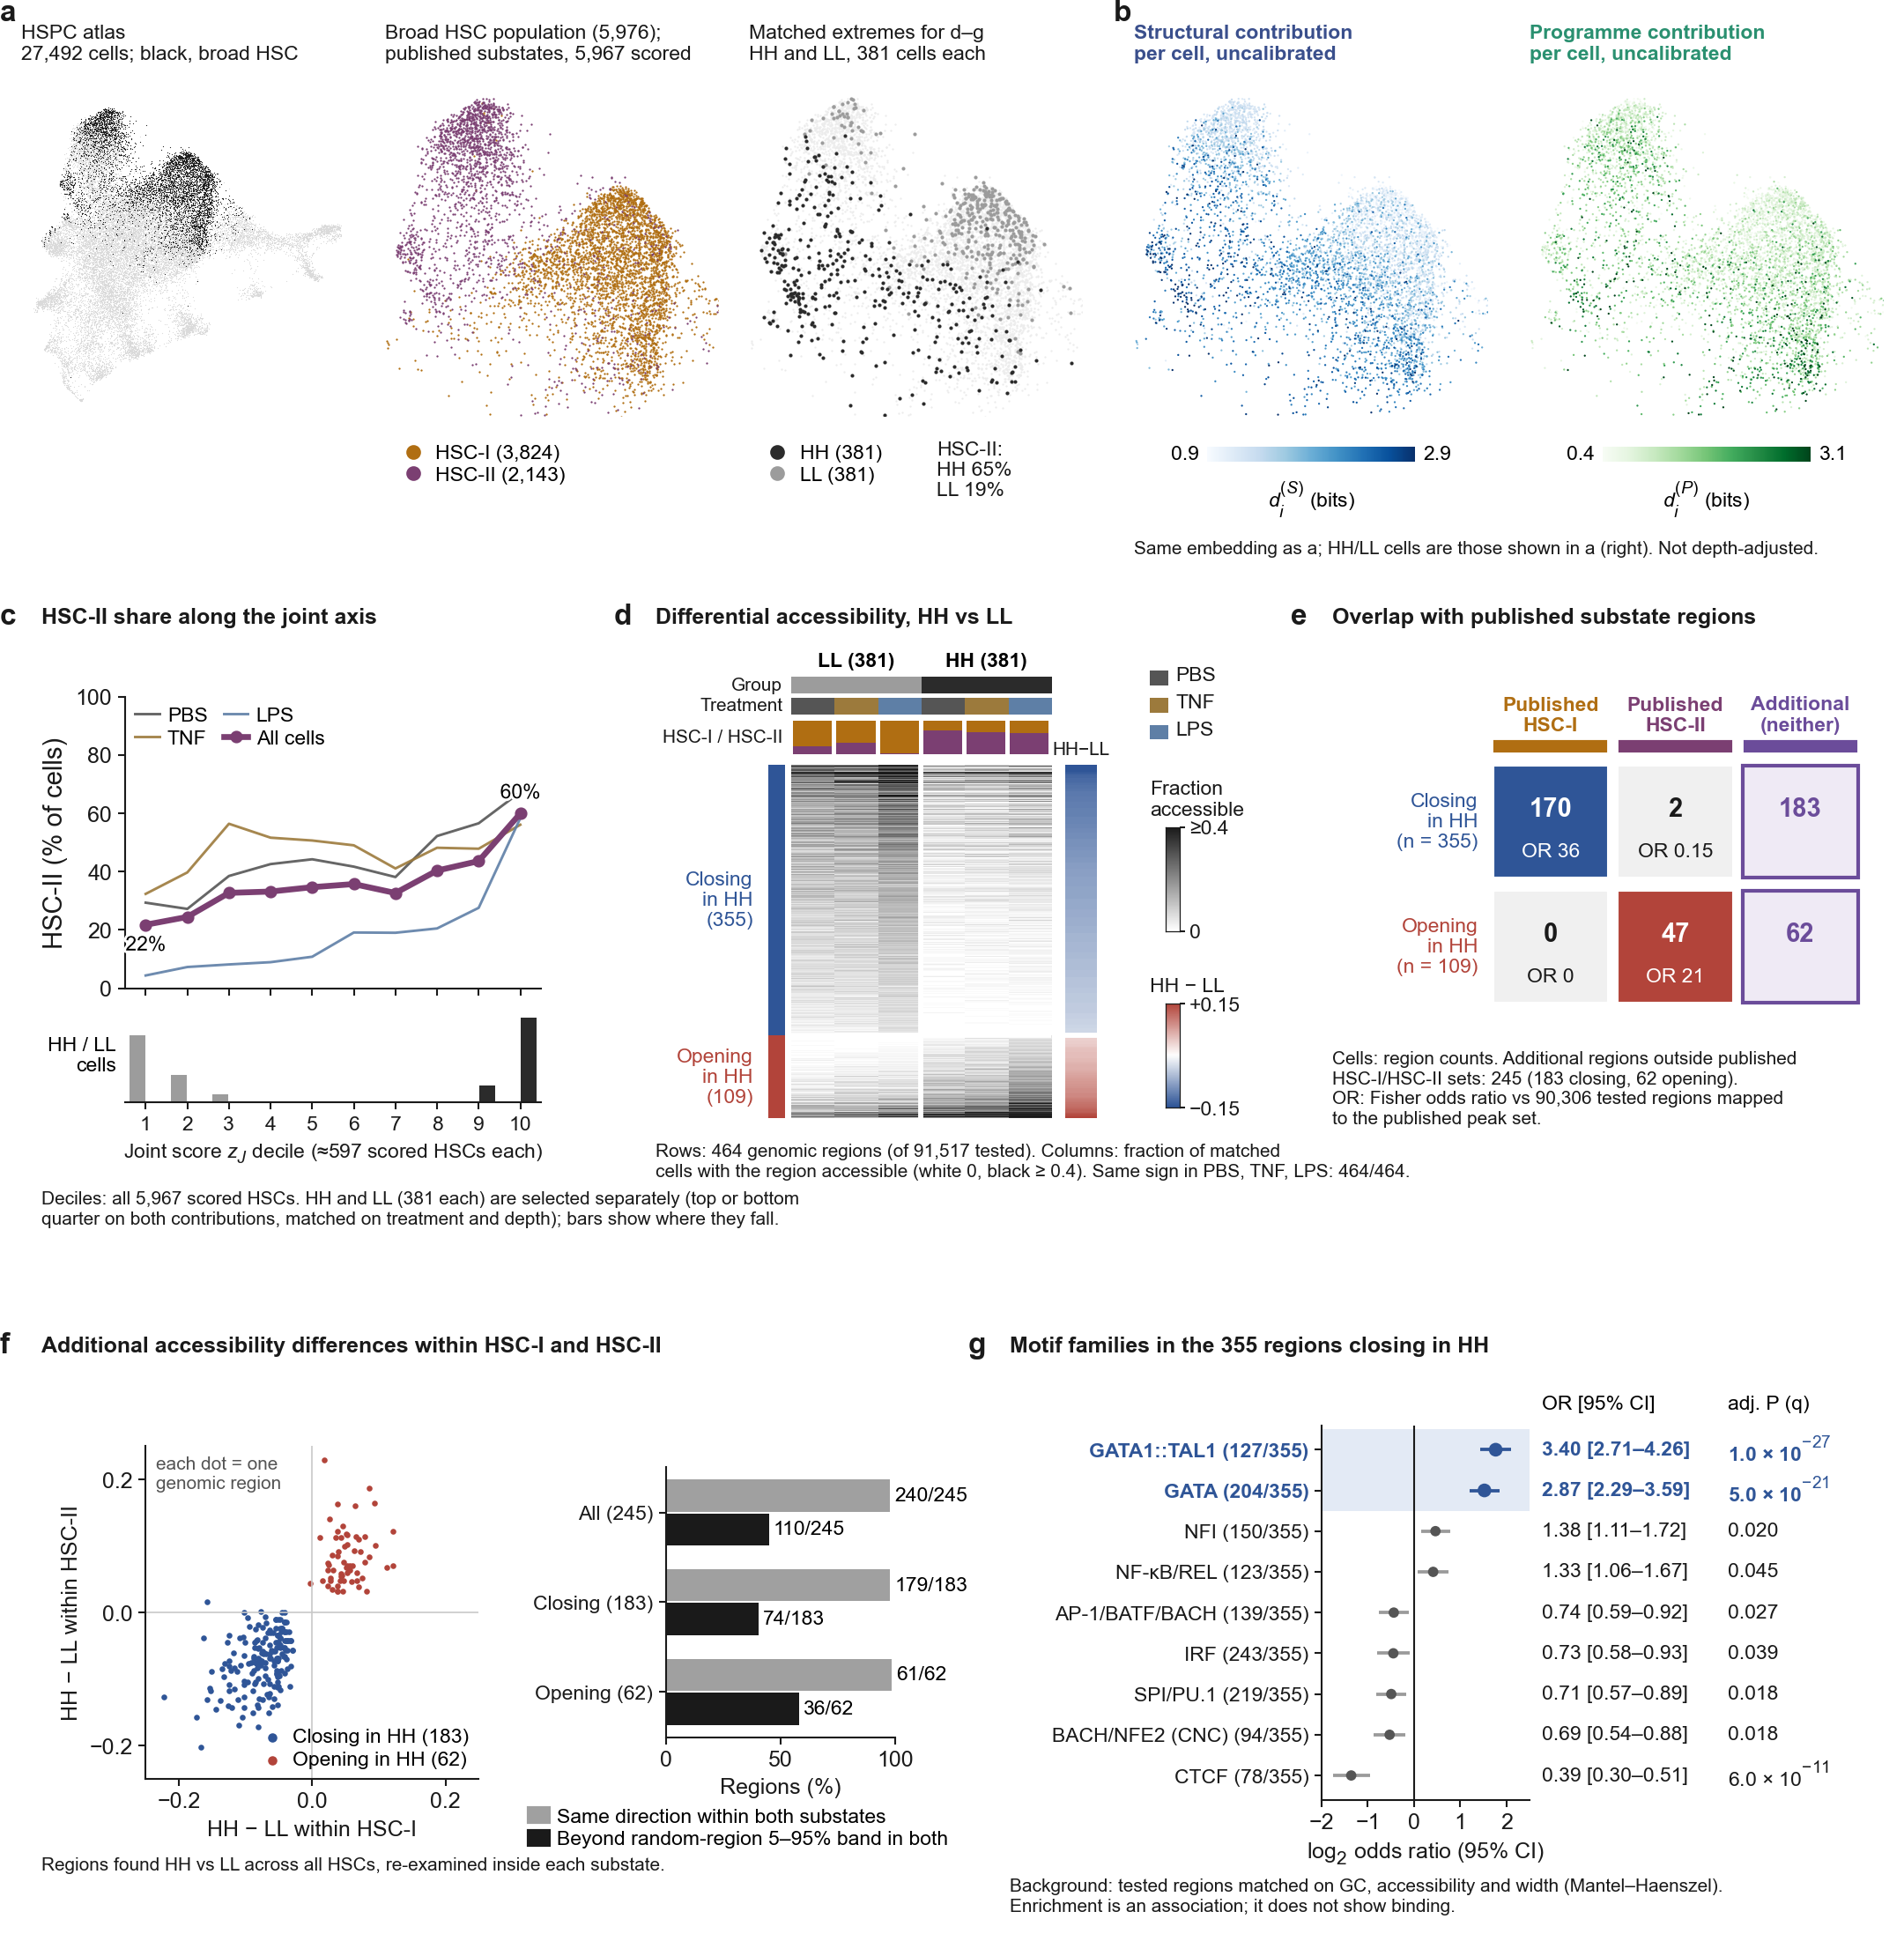

In [11]:
from IPython.display import display, Image
cv = build("Figure4", SIZE, [('a',PANELS['a'][0],PANELS['a'][1],panel_a),('b',PANELS['b'][0],PANELS['b'][1],panel_b),('c',PANELS['c'][0],PANELS['c'][1],panel_c),('d',PANELS['d'][0],PANELS['d'][1],panel_d),('e',PANELS['e'][0],PANELS['e'][1],panel_e),('f',PANELS['f'][0],PANELS['f'][1],panel_f),('g',PANELS['g'][0],PANELS['g'][1],panel_g)])
display(Image(filename=str(OUTPUT_DIR / "Figure4.png")))
plt.close(cv.fig)

## Figure S5

**Sensitivity checks.** Examine structural/programme relationships and robustness of the HSC contrasts to threshold selection using the reported output tables.

In [12]:
OUTPUT_DIR = ROOT / "figures" / "04_hsc"
FS_LETTER, FS_LABEL, FS_TICK, FS_ANN, FS_SMALL, FS_MIN = (fs.FS_LETTER,fs.FS_LABEL,fs.FS_TICK,fs.FS_ANN,fs.FS_SMALL,fs.FS_MIN)
GUIDE, INK, MUTED = fs.GUIDE, fs.INK, fs.MUTED
PROG, PROG_L, STRUCT, STRUCT_L = fs.PROG, fs.PROG_L, fs.STRUCT, fs.STRUCT_L
EPI, JAC, NEUTRAL_L = fs.EPI, fs.JAC, fs.NEUTRAL_L
fmt_p, short = fs.fmt_p, fs.short

import numpy as np
from scipy.stats import spearmanr
SIZE = (183, 114)
PANELS = {"a": (0, 0, 58, 54), "b": (60, 0, 70, 54), "c": (0, 58, 90, 54), "d": (92, 58, 91, 56)}
PANEL_REGIONS = PANELS
STATE = {"HSC-I": "#B06E12", "HSC-II": "#7B3F72"}
HH, LL = "#2B2B2B", "#9C9C9C"
OPEN, CLOSED = "#B2443A", "#2F5597"
R4 = "04_xenograft_HSC/results/"
joint = fs.read(R4 + "hsc_cell_joint_scores.tsv.gz", ["state", "d_S", "d_P", "u_S", "u_P"], 5967)
key4 = fs.read(R4 + "hsc_key_values.tsv", ["panel", "quantity", "value"])
th = fs.read(R4 + "hsc_threshold_sensitivity.tsv", ["q", "n_matched", "n_open", "n_closed", "frac_HSCII_HH", "frac_HSCII_LL",
                                                    "GATA_MH_OR_closed"], 6)
das = fs.read(R4 + "hsc_da_summary.tsv", ["contrast", "n_closed_in_high", "n_open_in_high"], 3).set_index("contrast")

### Plotting details

The functions below reproduce the manuscript design. They use the validated tables loaded above; random jitter and illustrative glyphs are display-only.

In [13]:
def title(P, s):
    P.text(4, 0.4, s, fontsize=FS_ANN, fontweight="bold", color=INK)

### Panel a — Cell-level distributions

In [14]:
def panel_a(P):
    title(P, "Structural vs programme contribution")
    ax = P.ax(13, 9, 38, 38)
    for st in ("HSC-I", "HSC-II"):
        d = joint[joint.state == st]
        ax.scatter(d.d_S, d.d_P, s=0.4, c=STATE[st], lw=0, alpha=0.6, rasterized=True, label=st)
    ax.set(xlabel="$d_i^{(S)}$ (bits)", ylabel="$d_i^{(P)}$ (bits)", xlim=(0.6, np.quantile(joint.d_S, 0.995)),
           ylim=(0, np.quantile(joint.d_P, 0.995)))
    v = key4.loc[key4.quantity == "Spearman d_S vs d_P (HSC)", "value"]; assert len(v) == 1
    r1 = printed("a", "Spearman d_S vs d_P", float(v.iloc[0]), ".2f", R4 + "hsc_key_values.tsv")
    r2 = printed("a", "within strata Spearman (u_S vs u_P)", float(spearmanr(joint.u_S, joint.u_P).statistic), ".2f",
                 "computed here from " + R4 + "hsc_cell_joint_scores.tsv.gz (u_S, u_P)")
    ax.text(0.97, 0.97, f"Spearman ρ = {r1}\nwithin strata ρ = {r2}", transform=ax.transAxes, ha="right", va="top",
            fontsize=FS_SMALL)
    ax.legend(loc="upper left", fontsize=FS_SMALL, markerscale=5, handletextpad=0.0, borderaxespad=0.1)

### Panel b — Population-level rankings

In [15]:
def panel_b(P):
    title(P, "Differential regions by selection strategy")
    ax = P.ax(24, 10, 34, 36)
    dd = das.loc[["joint", "programme", "structural"]]
    ax.axhspan(-0.45, 0.45, color="#EFEFEF", lw=0, zorder=0)
    ax.barh(range(3), -dd.n_closed_in_high, color=CLOSED, height=0.55)
    ax.barh(range(3), dd.n_open_in_high, color=OPEN, height=0.55)
    for i, (k, r) in enumerate(dd.iterrows()):
        txt = printed("b", f"{k} closing / opening", (int(r.n_closed_in_high), int(r.n_open_in_high)),
                      lambda v: f"{v[0]:,} / {v[1]:,}", R4 + "hsc_da_summary.tsv")
        c_t, o_t = txt.split(" / ")
        ax.text(-r.n_closed_in_high - 40, i, c_t, ha="right", va="center", fontsize=FS_SMALL)
        ax.text(r.n_open_in_high + 40, i, o_t, va="center", fontsize=FS_SMALL)
    ax.set_yticks(range(3), ["Joint HH vs LL\n(used in Fig. 4)", "Programme\nhigh vs low", "Structural\nhigh vs low"],
                  fontsize=FS_SMALL)
    ax.get_yticklabels()[0].set_fontweight("bold")
    ax.invert_yaxis(); ax.axvline(0, c=INK, lw=0.5)
    ax.set_xlim(-1700, 1000); ax.set_xticks([-1000, 0, 500], ["1,000", "0", "500"])
    ax.set_xlabel("Regions: closing | opening in high group", fontsize=FS_SMALL + 0.5)

### Panel c — Association or state composition

In [16]:
def panel_c(P):
    title(P, "Differential regions vs joint-tail threshold")
    ax = P.ax(14, 9, 64, 33)
    ax.plot(th.q, th.n_closed, "-o", c=CLOSED, ms=2, lw=0.8, label="Closing in HH")
    ax.plot(th.q, th.n_open, "-o", c=OPEN, ms=2, lw=0.8, label="Opening in HH")
    ax.axvline(0.25, ls=":", c=INK, lw=0.7)
    ax.text(0.252, ax.get_ylim()[1] * 0.97, "q = 0.25\n(Fig. 4)", fontsize=FS_SMALL, va="top")
    ax.set(xlabel="Joint tail quantile q (top/bottom q on both contributions)", ylabel="Differential regions",
           xticks=[0.1, 0.15, 0.2, 0.25, 0.3])
    ax.legend(loc="upper left", fontsize=FS_SMALL, handletextpad=0.2, handlelength=1.2)

### Panel d — Quantitative comparisons

In [17]:
def panel_d(P):
    title(P, "Robustness of the HSC-II and GATA associations")
    a1, a2 = P.ax(16, 9, 64, 14), P.ax(16, 28, 64, 14)
    a1.plot(th.q, 100 * th.frac_HSCII_HH, "-o", c=HH, ms=2, lw=0.8, label="HH")
    a1.plot(th.q, 100 * th.frac_HSCII_LL, "-o", c=LL, ms=2, lw=0.8, label="LL")
    a1.set(ylabel="HSC-II (%)", ylim=(0, 100), xticks=[0.1, 0.15, 0.2, 0.25, 0.3], yticks=[0, 50, 100]); a1.set_xticklabels([])
    a1.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), ncol=1, fontsize=FS_SMALL, handlelength=1.2, handletextpad=0.2,
              borderaxespad=0)
    a1.set_title("(i) HSC-II share of the matched groups", fontsize=FS_SMALL, loc="left", pad=2)
    g = th.dropna(subset=["GATA_MH_OR_closed"])
    a2.plot(g.q, g.GATA_MH_OR_closed, "-s", c=CLOSED, ms=2, lw=0.8)
    a2.set(xlabel="Joint tail quantile q", ylabel="GATA OR", ylim=(1, 3), xlim=a1.get_xlim(), xticks=[0.1, 0.15, 0.2, 0.25, 0.3])
    a2.set_title("(ii) GATA-family enrichment in closing regions", fontsize=FS_SMALL, loc="left", pad=2)
    for ax in (a1, a2):
        ax.axvline(0.25, ls=":", c=INK, lw=0.7)
    few = printed("d", "closing regions at q = 0.10, 0.15", (int(th.n_closed.iloc[0]), int(th.n_closed.iloc[1])),
                  lambda v: f"{v[0]} and {v[1]}", R4 + "hsc_threshold_sensitivity.tsv")
    nm = printed("d", "matched cells per group", tuple(int(n) for n in th.n_matched), lambda v: ", ".join(map(str, v)),
                 R4 + "hsc_threshold_sensitivity.tsv")
    P.text(16, 50.5, f"No OR reported at q ≤ 0.15 (only {few} closing regions).\nMatched cells per group at each q: {nm}.",
           fontsize=FS_MIN, color=MUTED, linespacing=1.25)

### Render and inspect

Export the full assembled manuscript figure as vector PDF/SVG and a PNG preview. Inspect labels and plot boundaries before publication.

figures/04_hsc/FigureS5.pdf
figures/04_hsc/FigureS5.svg
figures/04_hsc/FigureS5.png


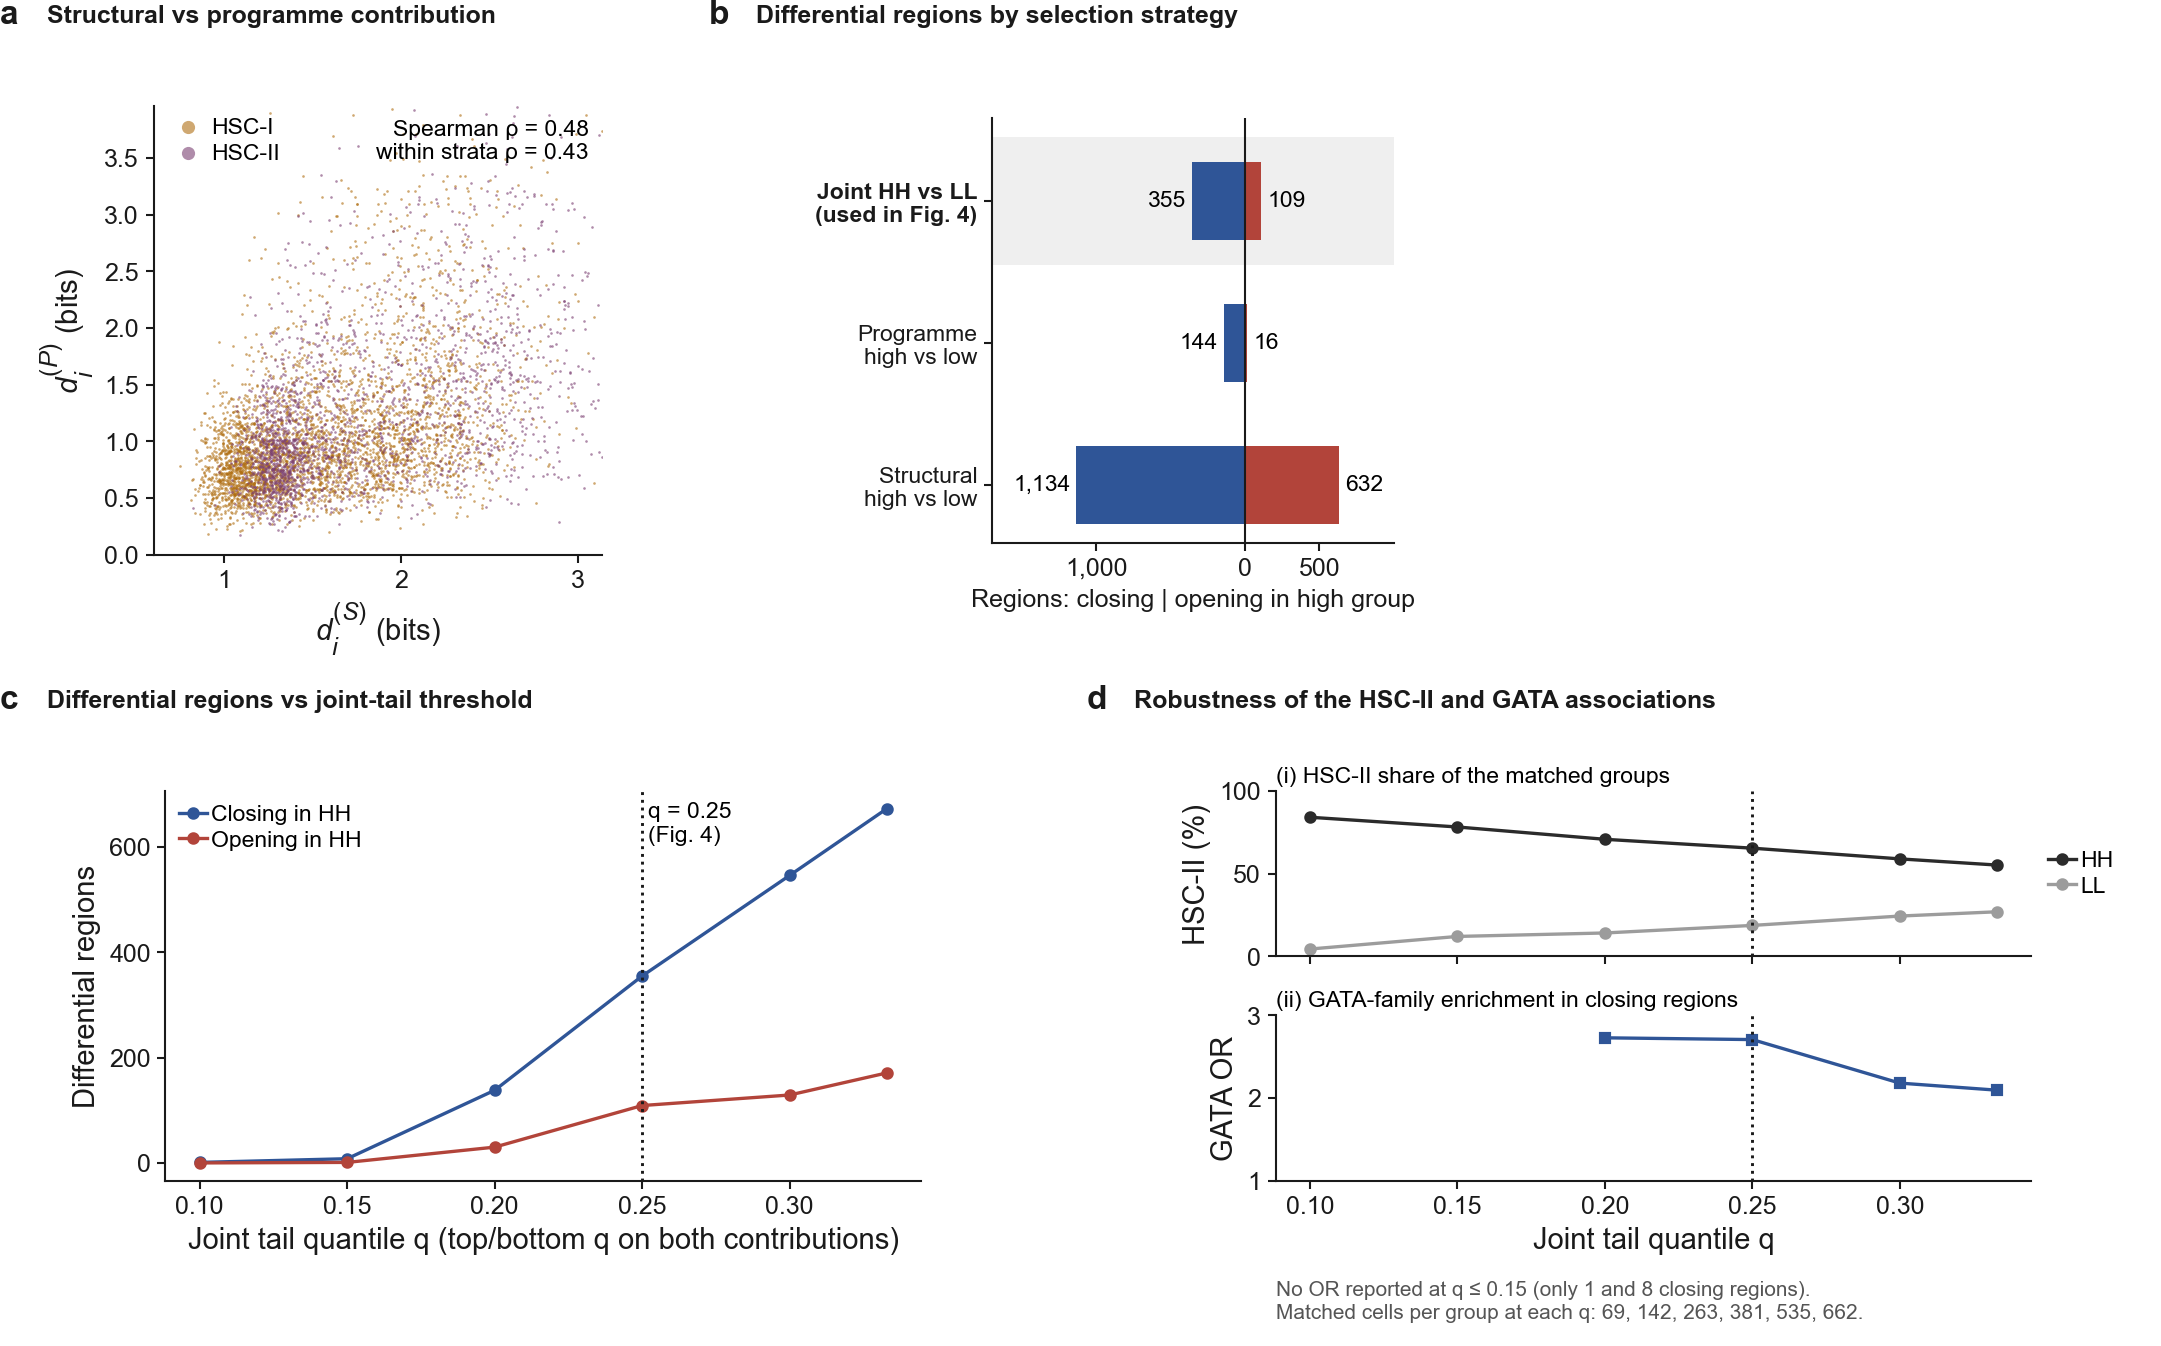

In [18]:
from IPython.display import display, Image
cv = build("FigureS5", SIZE, [('a',PANELS['a'][0],PANELS['a'][1],panel_a),('b',PANELS['b'][0],PANELS['b'][1],panel_b),('c',PANELS['c'][0],PANELS['c'][1],panel_c),('d',PANELS['d'][0],PANELS['d'][1],panel_d)])
display(Image(filename=str(OUTPUT_DIR / "FigureS5.png")))
plt.close(cv.fig)

## Figure S6

**Regulatory follow-up.** Compare HSC-associated region sets, published markers and accessibility gradients with the validated HSC analysis tables.

In [19]:
OUTPUT_DIR = ROOT / "figures" / "04_hsc"
FS_LETTER, FS_LABEL, FS_TICK, FS_ANN, FS_SMALL, FS_MIN = (fs.FS_LETTER,fs.FS_LABEL,fs.FS_TICK,fs.FS_ANN,fs.FS_SMALL,fs.FS_MIN)
GUIDE, INK, MUTED = fs.GUIDE, fs.INK, fs.MUTED
PROG, PROG_L, STRUCT, STRUCT_L = fs.PROG, fs.PROG_L, fs.STRUCT, fs.STRUCT_L
EPI, JAC, NEUTRAL_L = fs.EPI, fs.JAC, fs.NEUTRAL_L
fmt_p, short = fs.fmt_p, fs.short

import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
SIZE = (183, 178)
PANELS = {"a": (0, 0, 56, 58), "b": (58, 0, 125, 58), "c": (0, 62, 183, 116)}
PANEL_REGIONS = PANELS
OPEN, CLOSED = "#B2443A", "#2F5597"
R4 = "04_xenograft_HSC/results/"
ovl = fs.read(R4 + "hsc_published_overlap_statistics.tsv", ["contrast", "region_set", "published_set", "odds_ratio"], 12)
gr = fs.read(R4 + "hsc_regionset_gradient_by_zJ_decile.tsv", ["region_set", "state", "z_decile", "mean_rel"])

### Plotting details

The functions below reproduce the manuscript design. They use the validated tables loaded above; random jitter and illustrative glyphs are display-only.

In [20]:
def title(P, s):
    P.text(4, 0.4, s, fontsize=FS_ANN, fontweight="bold", color=INK)

### Panel a — Cell-level distributions

In [21]:
def panel_a(P):
    title(P, "Overlap with published substate region sets")
    ax = P.ax(12, 10, 38, 34)
    cs = ["structural", "programme", "joint"]
    for j, (rs, ps_, lab, c, key) in enumerate((
            ("closed_in_high", "published_HSCI", "Closing in high ∩ published HSC-I", CLOSED, "closing x published HSC-I"),
            ("open_in_high", "published_HSCII", "Opening in high ∩ published HSC-II", OPEN, "opening x published HSC-II"))):
        v = ovl[(ovl.region_set == rs) & (ovl.published_set == ps_)].set_index("contrast").loc[cs]
        txt = printed("a", f"OR {key}: structural / programme / joint", tuple(v.odds_ratio),
                      lambda t: " / ".join(f"{x:.0f}" for x in t), R4 + "hsc_published_overlap_statistics.tsv")
        ax.bar(np.arange(3) + (j - 0.5) * 0.36, v.odds_ratio, 0.34, color=c, label=lab)
        for k, (cc, t) in enumerate(zip(cs, txt.split(" / "))):
            ax.text(k + (j - 0.5) * 0.36, v.loc[cc, "odds_ratio"] + 0.6, t, ha="center", va="bottom", fontsize=FS_MIN)
    ax.axhspan(0, 1, color="#EFEFEF", lw=0, zorder=0); ax.axhline(1, c=INK, lw=0.5, ls=":")
    ax.set_xticks(range(3), ["Structural", "Programme", "Joint\n(Fig. 4)"]); ax.get_xticklabels()[2].set_fontweight("bold")
    ax.set(ylabel="Fisher odds ratio", ylim=(0, 58))
    ax.legend(loc="upper left", fontsize=FS_SMALL, handlelength=1.0, borderaxespad=0.1)

### Panel b — Population-level rankings

In [22]:
def panel_b(P):
    title(P, "Accessibility along the joint axis, within each substate")
    sets = {"closed": [("closed, in published HSC-I", "In published HSC-I set", "#8FA8D0"),
                       ("closed, additional", "Additional", CLOSED)],
            "open": [("open, in published HSC-II", "In published HSC-II set", "#E0A39C"),
                     ("open, additional", "Additional", OPEN)]}
    ylab = printed("b", "y-axis label", "Relative accessibility (log$_2$)", "", "frozen label (see note)", flag=True)
    for k, (key, ttl) in enumerate((("closed", "Regions closing in HH"), ("open", "Regions opening in HH"))):
        ax = P.ax(14 + k * 52, 10, 42, 34)
        for rs, lab, c in sets[key]:
            for st, ls in (("HSC-I", "-"), ("HSC-II", "--")):
                g = gr[(gr.region_set == rs) & (gr.state == st)].sort_values("z_decile")
                assert len(g) == 10, (rs, st)
                ax.plot(g.z_decile + 1, g.mean_rel, ls=ls, c=c, lw=0.9)
        ax.set(xlabel="$z_J$ decile", xticks=[1, 4, 7, 10], ylim=(0.8, 4.3))
        if k == 0:
            ax.set_ylabel(ylab)
        else:
            ax.set_yticklabels([])
        ax.set_title(ttl, fontsize=FS_SMALL, loc="left", pad=2, color=CLOSED if key == "closed" else OPEN)
        hh = [Line2D([], [], c=c, lw=0.9, label=lab) for _, lab, c in sets[key]]
        ax.legend(handles=hh, loc="lower left" if key == "closed" else "upper left", fontsize=FS_SMALL, handlelength=1.2,
                  borderaxespad=0.1, handletextpad=0.3)
    lgd = P.ax(14, 53, 90, 4); fs.blank(lgd)
    lgd.legend(handles=[Line2D([], [], c=INK, ls="-", lw=0.9, label="Within HSC-I cells"),
                        Line2D([], [], c=INK, ls="--", lw=0.9, label="Within HSC-II cells")], loc="upper left", ncol=2,
               fontsize=FS_SMALL, handlelength=2, borderaxespad=0)

### Panel c — Association or state composition

In [23]:
# Figure S6c — original manuscript representative tracks from frozen tables.
# The nine files are copied unchanged from final_manuscript_package_v1/Figure4_revision/tracks/source_tables.
TRACK_DIR = ROOT / "data" / "hsc_tracks"
track_ids = ("C1", "C2", "C3", "O1", "O2", "O3")
required = ["representative_regions.tsv", "representative_regions_motif_sites.tsv", "motif_family_driver_regions.tsv"] + [f"track_{rid}.tsv" for rid in track_ids]
missing = [name for name in required if not (TRACK_DIR / name).is_file()]
assert not missing, f"Missing frozen inputs in {TRACK_DIR}: {missing}"

rep = pd.read_csv(TRACK_DIR / "representative_regions.tsv", sep="\t").set_index("rep_id")
sites = pd.read_csv(TRACK_DIR / "representative_regions_motif_sites.tsv", sep="\t")
drv = pd.read_csv(TRACK_DIR / "motif_family_driver_regions.tsv", sep="\t")
assert set(rep.index) == set(track_ids), "Representative-region IDs differ from manuscript figure"
# Use the saved matching information, NOT the author-substate composition of the complete atlas.
matched = fs.read("04_xenograft_HSC/results/hsc_hh_ll_matched_cells.tsv", ["group", "state"], 762)
NG = matched.groupby(["group", "state"]).size()
assert set(NG.index.get_level_values(0)) == {"HH", "LL"}
assert set(NG.index.get_level_values(1)) == {"HSC-I", "HSC-II"}
assert NG.loc["HH"].sum() == NG.loc["LL"].sum() == 381
hit = {
    fam: set(";".join(drv[(drv.region_set.astype(str).str.startswith(("D", "F"))) & (drv.family == fam)].hit_regions.dropna().astype(str)).split(";"))
    for fam in ("GATA", "GATA1::TAL1")
}

# Existing notebook colours / geometry are retained; data come from original frozen tables.
def panel_c(P):
    title(P, "Representative additional regions: matched HH vs LL pseudobulk accessibility within each substate")
    P.text(4, 4.6, "Six regions selected a priori (additional; same sign within HSC-I, HSC-II and all treatments; "
           "top 3 per direction by q, ≥ 250 kb apart).", fontsize=FS_MIN)
    for n, rid in enumerate(("C1", "C2", "C3", "O1", "O2", "O3")):
        r = rep.loc[rid]
        t = pd.read_csv(TRACK_DIR / f"track_{rid}.tsv", sep="\t")
        expected_cols = {"bin_mid", "LL|HSC-I", "HH|HSC-I", "LL|HSC-II", "HH|HSC-II"}
        assert expected_cols <= set(t.columns), (rid, expected_cols - set(t.columns))
        assert len(t) == 160 and t.bin_mid.is_monotonic_increasing, rid
        sm = t.set_index("bin_mid").rolling(5, center=True, min_periods=1).mean()  # 250 bp, frozen design
        col, row = n % 3, n // 3
        x0, y0 = 4 + col * 60, 11 + row * 48
        start, end = int(r.start), int(r.end)
        ymax = float(sm.max().max()) * 1.08
        assert np.isfinite(ymax) and ymax > 0, rid
        closed = str(r["class"]).startswith("CLOSED")
        fam_sites = sites[sites.rep_id == rid]
        if closed:
            fams = [fam for fam in ("GATA", "GATA1::TAL1") if r.region in hit[fam]]
            assert fams and set(fam_sites.family) <= set(fams) | {"GATA", "GATA1::TAL1"}, rid
        gene = r["nearest_pc_gene (proximity only)"]
        dist = float(r.signed_dist_to_nearest_pc_TSS_bp)
        P.text(x0, y0 + 0.2, f"{rid}  {r.chrom}:{start:,}–{end:,}",
               fontsize=FS_SMALL, fontweight="bold", color=CLOSED if closed else OPEN)
        P.text(x0, y0 + 3.0,
               f"{'Closing' if closed else 'Opening'} in HH; HH−LL {r.HH_minus_LL_frac_open:+.2f} "
               f"(q = {r.HH_LL_q:.1g}); nearest gene {gene} ({dist / 1e3:+.0f} kb)", fontsize=FS_MIN)
        for k, state in enumerate(("HSC-I", "HSC-II")):
            ax = P.ax(x0 + 9, y0 + 7.5 + k * 13.5, 46, 11)
            ax.axvspan(start, end, color="#F3E7B8" if closed else "#F6DDD8", lw=0, zorder=0)
            ax.fill_between(sm.index.to_numpy(), sm[f"LL|{state}"].to_numpy(),
                            color="#9C9C9C", alpha=0.55, lw=0)
            ax.plot(sm.index.to_numpy(), sm[f"HH|{state}"].to_numpy(), color="#2B2B2B", lw=0.9)
            ax.set_xlim(t.bin_mid.min() - 25, t.bin_mid.max() + 25)
            ax.set_ylim(0, ymax)
            ax.set_yticks([0, round(ymax * 0.9, 1)])
            ax.tick_params(labelsize=FS_MIN, length=1.5, pad=1)
            ax.set_xticks([])
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
            ax.text(-0.02, 0.5, f"within\n{state}", transform=ax.transAxes,
                    ha="right", va="center", fontsize=FS_MIN,
                    color={"HSC-I": "#E06E12", "HSC-II": "#7B3F72"}[state])
            ax.text(0.01, 0.97, f"HH n = {NG.loc[('HH', state)]} · LL n = {NG.loc[('LL', state)]}",
                    transform=ax.transAxes, ha="left", va="top", fontsize=FS_MIN, color=MUTED)
        mx = P.ax(x0 + 9, y0 + 34.2, 46, 2.6)
        mx.set_xlim(t.bin_mid.min() - 25, t.bin_mid.max() + 25)
        mx.set_ylim(0, 1)
        fs.blank(mx)
        mx.plot([t.bin_mid.min(), t.bin_mid.max()], [0.5, 0.5], color=GUIDE, lw=0.4)
        mx.add_patch(Rectangle((start, 0.25), end - start, 0.5, color="#CFCFCF", lw=0))
        for _, sres in fam_sites.iterrows():
            mx.add_patch(Rectangle((sres.start - 40, 0), (sres.end - sres.start) + 80, 1,
                                   color=CLOSED, lw=0))
        fam_lab = (" + ".join(sorted(set(fam_sites.family))) + "-family motif sites") if len(fam_sites) else "no GATA-family site"
        mx.text(-0.02, 0.5, "motifs", transform=mx.transAxes, ha="right", va="center", fontsize=FS_MIN)
        mx.text(0, -0.6, fam_lab if closed else "(motif sites shown for closing regions only)",
                transform=mx.transAxes, ha="left", va="top", fontsize=FS_MIN,
                color=CLOSED if closed else MUTED)
        mx.text(1, -0.6, f"{(t.bin_mid.max() - t.bin_mid.min() + 50) / 1e3:.0f} kb window",
                transform=mx.transAxes, ha="right", va="top", fontsize=FS_MIN, color=MUTED)
    handles = [Line2D([], [], color="#2B2B2B", lw=0.9, label="HH (matched high-contribution)"),
               Rectangle((0, 0), 1, 1, color="#9C9C9C", alpha=0.55, label="LL (matched low-contribution)"),
               Rectangle((0, 0), 1, 1, color="#F3E7B8", label="tested differential region"),
               Rectangle((0, 0), 1, 1, color=CLOSED, label="GATA-family motif site")]
    lg = P.ax(4, 108, 175, 4)
    fs.blank(lg)
    lg.legend(handles=handles, loc="upper left", ncol=4, fontsize=FS_SMALL,
              handlelength=1.6, borderaxespad=0, columnspacing=1.2)


### Render and inspect

Export the full assembled manuscript figure as vector PDF/SVG and a PNG preview. Inspect labels and plot boundaries before publication.

figures/04_hsc/FigureS6.pdf
figures/04_hsc/FigureS6.svg
figures/04_hsc/FigureS6.png


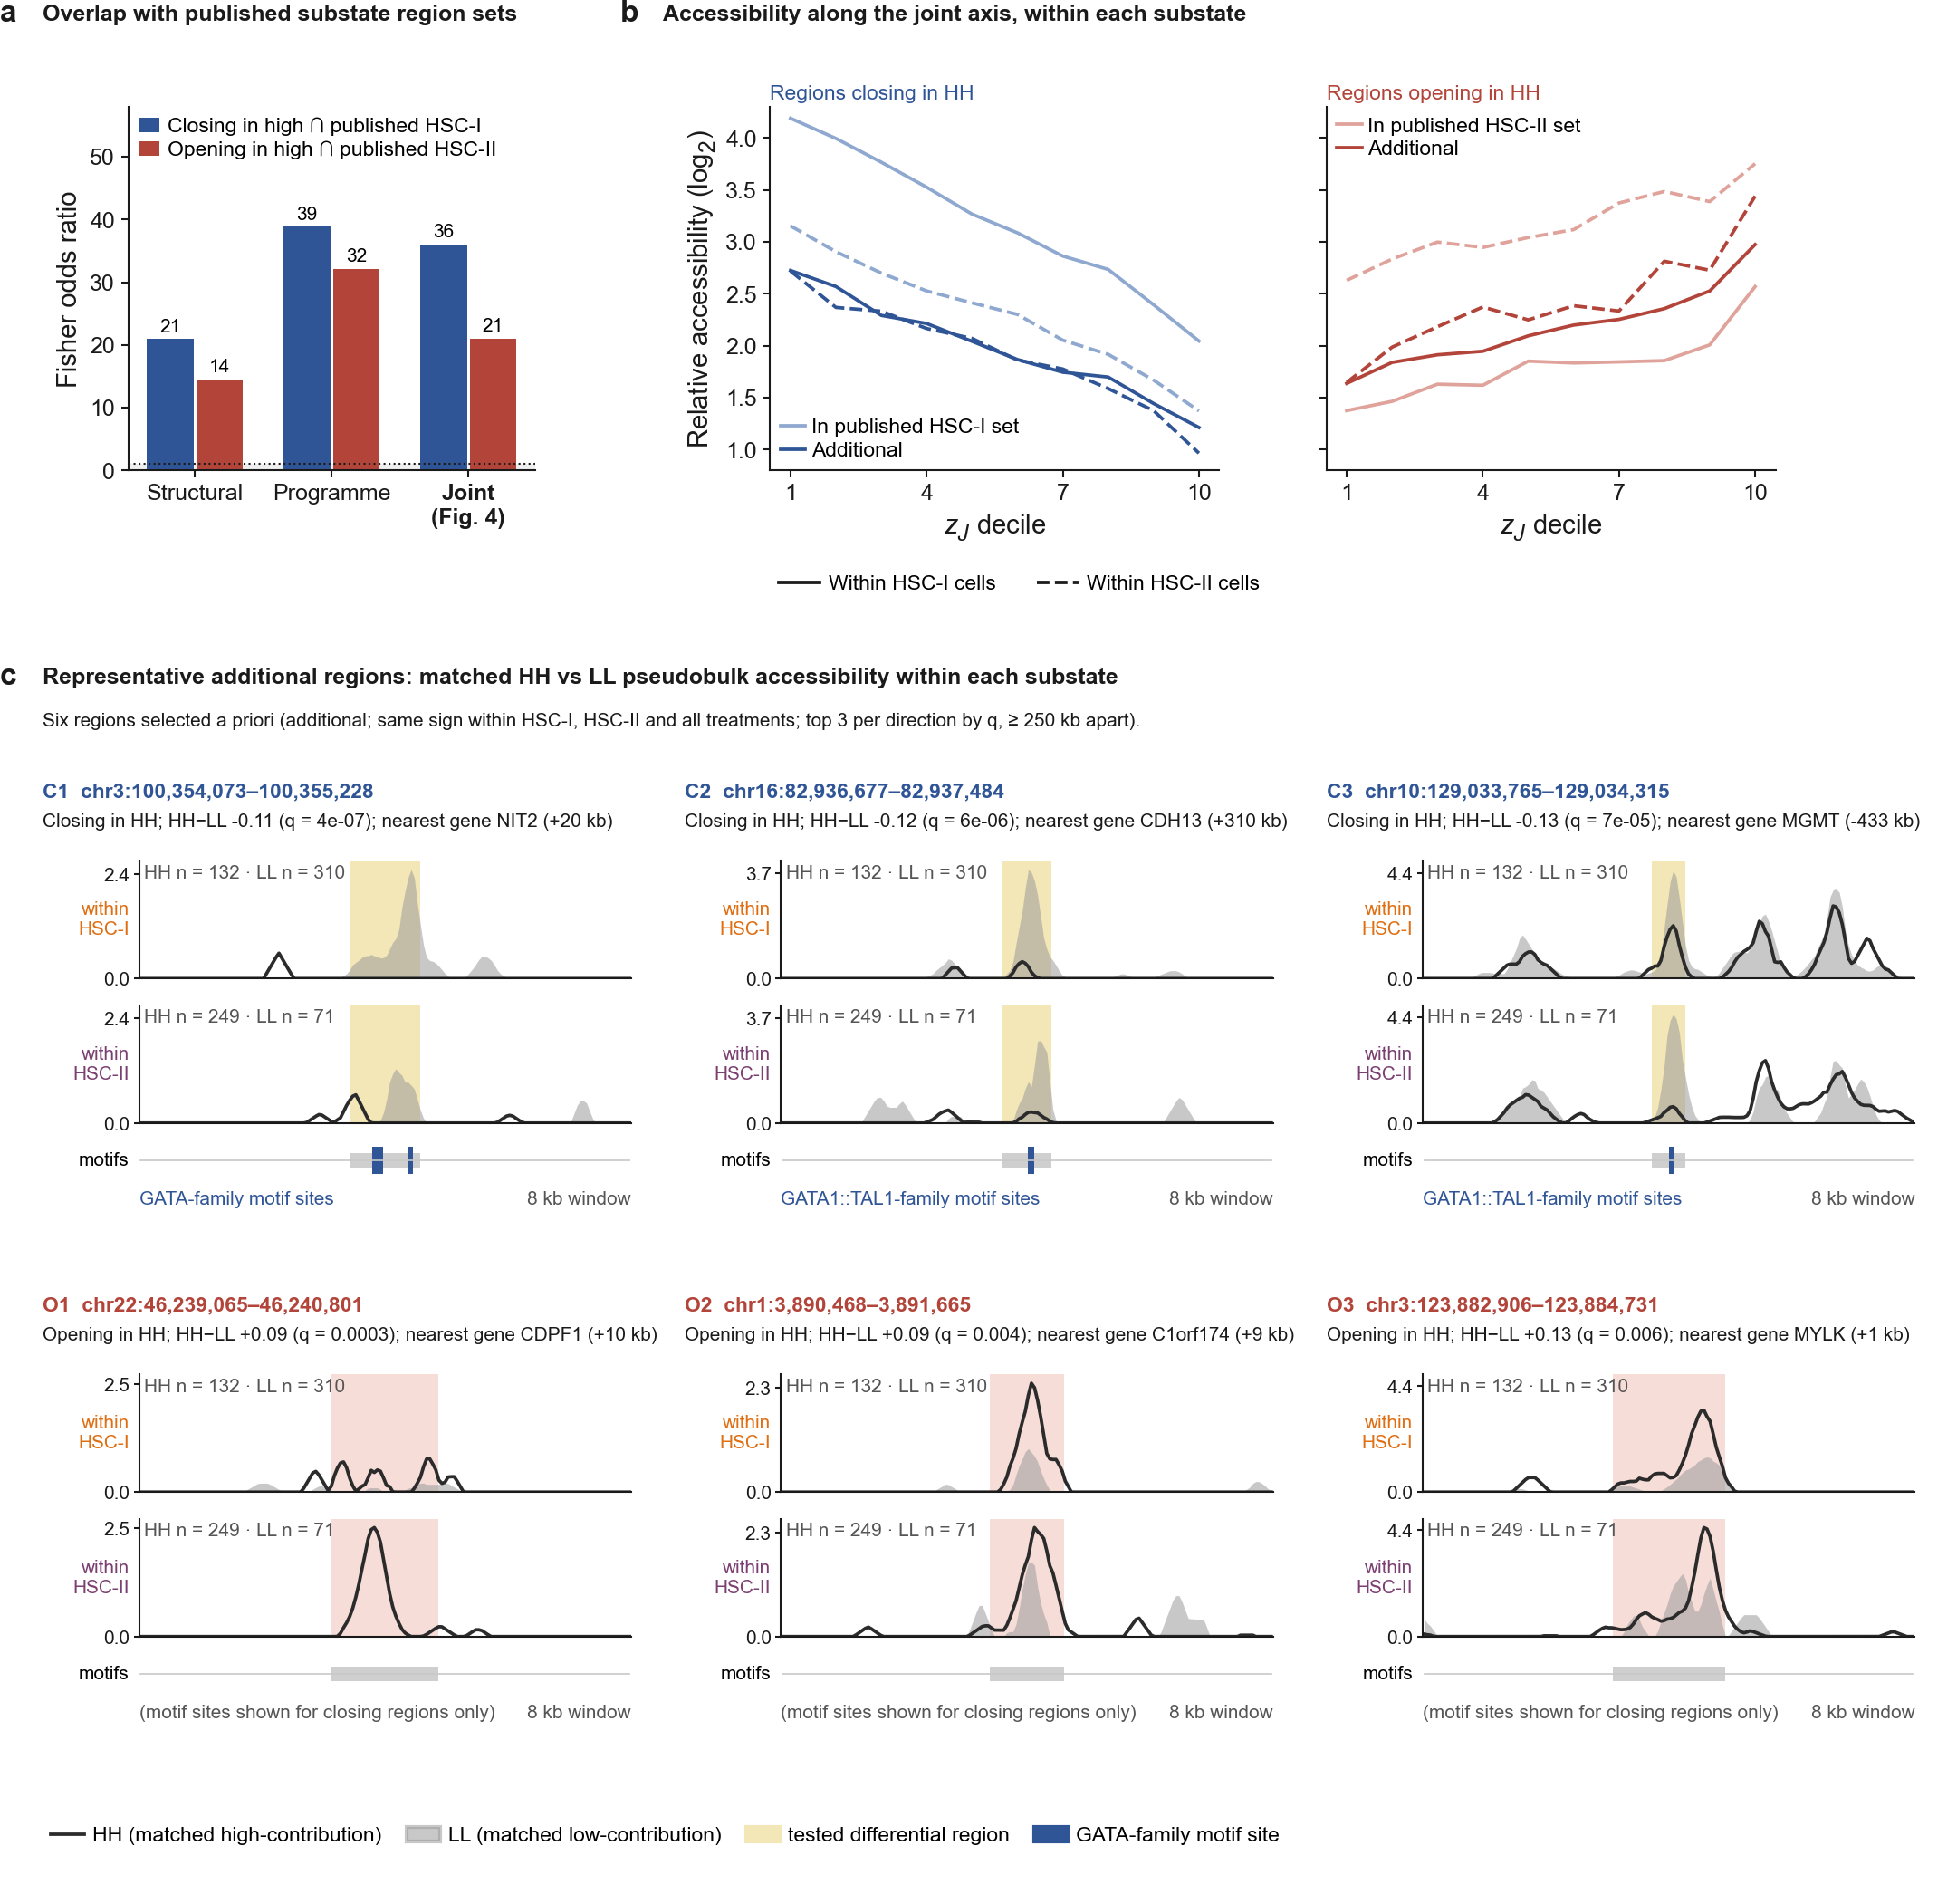

In [24]:
from IPython.display import display, Image
cv = build("FigureS6", SIZE, [('a',PANELS['a'][0],PANELS['a'][1],panel_a),('b',PANELS['b'][0],PANELS['b'][1],panel_b),('c',PANELS['c'][0],PANELS['c'][1],panel_c)])
display(Image(filename=str(OUTPUT_DIR / "FigureS6.png")))
plt.close(cv.fig)